In [1]:
import os
from collections import Counter

ROOT = "F:/drthesis"
IMG_EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

def summarize(path, depth=0, max_depth=6):
    if depth > max_depth:
        return
    try:
        entries = sorted(os.listdir(path))
    except PermissionError:
        return
    dirs  = [e for e in entries if os.path.isdir(os.path.join(path, e)) and not e.startswith(".")]
    files = [e for e in entries if os.path.isfile(os.path.join(path, e))]
    exts  = Counter(os.path.splitext(f)[1].lower() for f in files)
    n_img = sum(c for e, c in exts.items() if e in IMG_EXT)
    others = [f for f in files if os.path.splitext(f)[1].lower() not in IMG_EXT][:5]
    print("  " * depth + f"{os.path.basename(path) or path}/  "
          f"[{n_img} images, {len(files) - n_img} other files {dict(exts)}]"
          + (f"  e.g. {others}" if others else ""))
    for d in dirs:
        summarize(os.path.join(path, d), depth + 1, max_depth)

summarize(ROOT)

drthesis/  [0 images, 1 other files {'.ipynb': 1}]  e.g. ['Untitled.ipynb']
  APTOS/  [0 images, 0 other files {}]
    aptos2019-blindness-detection/  [0 images, 3 other files {'.csv': 3}]  e.g. ['sample_submission.csv', 'test.csv', 'train.csv']
      test_images/  [1928 images, 0 other files {'.png': 1928}]
      train_images/  [3662 images, 0 other files {'.png': 3662}]
  DDR/  [0 images, 9 other files {'.002': 1, '.003': 1, '.004': 1, '.005': 1, '.006': 1, '.007': 1, '.008': 1, '.009': 1, '.010': 1}]  e.g. ['DDR-dataset.zip.002', 'DDR-dataset.zip.003', 'DDR-dataset.zip.004', 'DDR-dataset.zip.005', 'DDR-dataset.zip.006']
    DDR-dataset/  [0 images, 0 other files {}]
      DDR-dataset/  [0 images, 0 other files {}]
        DR_grading/  [0 images, 3 other files {'.txt': 3}]  e.g. ['test.txt', 'train.txt', 'valid.txt']
          test/  [4105 images, 0 other files {'.jpg': 4105}]
          train/  [6835 images, 0 other files {'.jpg': 6835}]
          valid/  [2733 images, 0 other files 

In [2]:
summarize("F:/drthesis/DDR/DDR-dataset/DDR-dataset/lesion_segmentation", max_depth=3)

lesion_segmentation/  [0 images, 0 other files {}]
  test/  [0 images, 0 other files {}]
    image/  [225 images, 0 other files {'.jpg': 225}]
    label/  [0 images, 0 other files {}]
      EX/  [225 images, 0 other files {'.tif': 225}]
      HE/  [225 images, 0 other files {'.tif': 225}]
      MA/  [225 images, 0 other files {'.tif': 225}]
      SE/  [225 images, 0 other files {'.tif': 225}]
  train/  [0 images, 0 other files {}]
    image/  [383 images, 0 other files {'.jpg': 383}]
    label/  [0 images, 0 other files {}]
      EX/  [383 images, 0 other files {'.tif': 383}]
      HE/  [383 images, 0 other files {'.tif': 383}]
      MA/  [383 images, 0 other files {'.tif': 383}]
      SE/  [383 images, 0 other files {'.tif': 383}]
  valid/  [0 images, 0 other files {}]
    image/  [149 images, 0 other files {'.jpg': 149}]
    segmentation label/  [0 images, 0 other files {}]
      EX/  [149 images, 0 other files {'.tif': 149}]
      HE/  [149 images, 0 other files {'.tif': 149}]
     

In [3]:
   %run F:/drthesis/code/01_prepare_data.py

Project folder: F:\drthesis

1. DDR grading splits
  train:  6260 images kept | removed 575 ungradable | missing files: 0 | grades {0: 3133, 1: 315, 2: 2238, 3: 118, 4: 456}
  valid:  2503 images kept | removed 230 ungradable | missing files: 0 | grades {0: 1253, 1: 126, 2: 895, 3: 47, 4: 182}
  test :  3759 images kept | removed 346 ungradable | missing files: 0 | grades {0: 1880, 1: 189, 2: 1344, 3: 71, 4: 275}

2. IDRiD grading (external test)
  516 graded images | missing files: 0 | grades {0: 168, 1: 25, 2: 168, 3: 93, 4: 62}

3. APTOS + near-duplicate check
  3662 labelled images | grades {0: 1805, 1: 370, 2: 999, 3: 193, 4: 295}
  hashing 3662 APTOS images ...
  duplicate pairs found: 148 | duplicate groups: 131 | groups with conflicting grades (all dropped): 37
  APTOS after de-duplication: 3486 images | grades {0: 1796, 1: 338, 2: 921, 3: 167, 4: 264}

4. IDRiD overlap check (lesion images vs grading images)
  hashing 81 IDRiD lesion images ...
  hashing 516 IDRiD grading imag

DDR: image width  min 1380  median 2592  max 5184
DDR: boxes per image  median 49  max 1453  images with >300 boxes: 73
IDRiD: image width  min 4288  median 4288  max 4288
IDRiD: boxes per image  median 145  max 630  images with >300 boxes: 20


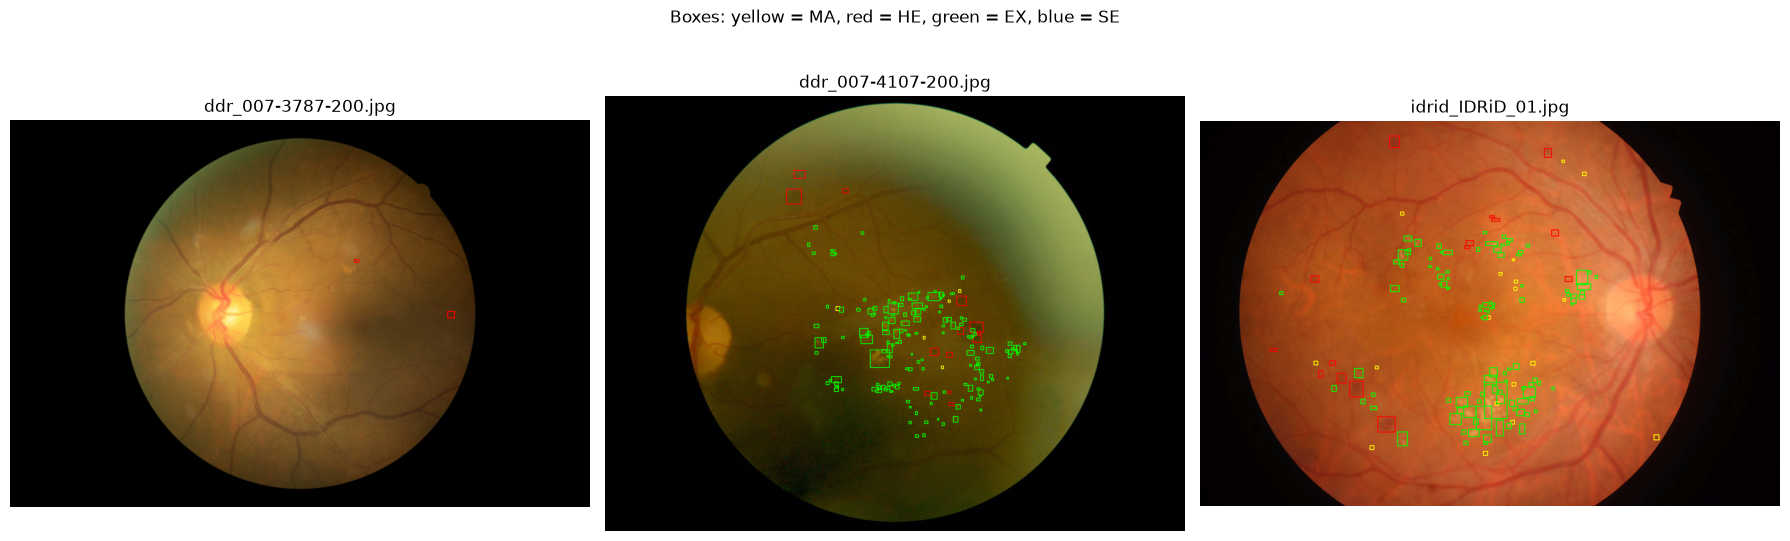

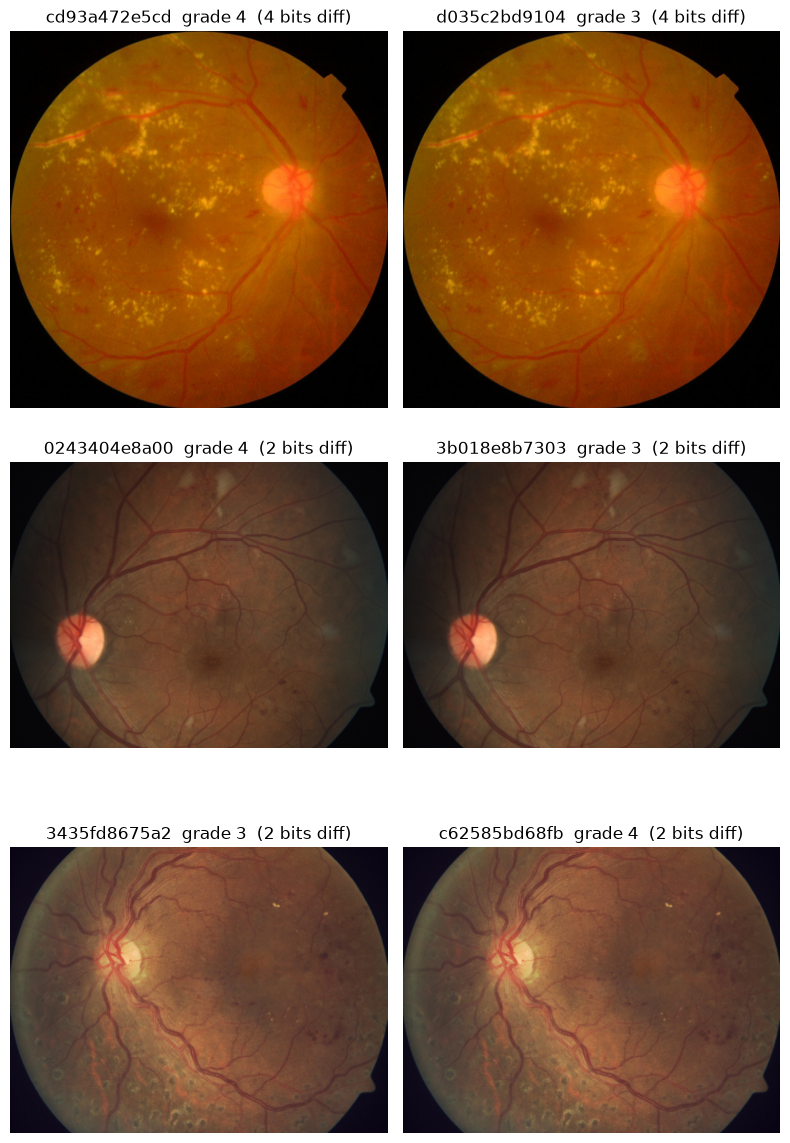

In [4]:
   %run F:/drthesis/code/check_cell.py

In [5]:
   %run F:/drthesis/code/02_eval_detector.py baseline640 640

Found 3 runs: ['baseline640_s0', 'baseline640_s1', 'baseline640_s2']  |  imgsz=640

Ultralytics 8.4.208  Python-3.11.18 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients
val: Fast image access  (ping: 0.1±0.0 ms, read: 169.7±116.6 MB/s, size: 1009.3 KB)
val: Scanning F:\drthesis\processed\yolo_full\labels\test_ddr... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 928.3it/s 0.2s0.1s
val: New cache created: F:\drthesis\processed\yolo_full\labels\test_ddr.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 6.1it/s 4.7s0.1s
                   all        225      17032      0.265      0.176      0.103     0.0418
Speed: 0.1ms preprocess, 2.3ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.208  Python-3.11.18 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
Model summary (fused): 73 layers, 3,133,

In [6]:
import pandas as pd
b = pd.read_csv("F:/drthesis/splits/lesion_boxes_all.csv").drop_duplicates("image")
print(b.groupby("source")[["w", "h"]].describe(percentiles=[.1, .5, .9]).round(0).T)

source      DDR   IDRiD
w count   757.0    81.0
  mean   2612.0  4288.0
  std     592.0     0.0
  min    1380.0  4288.0
  10%    2048.0  4288.0
  50%    2592.0  4288.0
  90%    3456.0  4288.0
  max    5184.0  4288.0
h count   757.0    81.0
  mean   1912.0  2848.0
  std     433.0     0.0
  min    1088.0  2848.0
  10%    1536.0  2848.0
  50%    1824.0  2848.0
  90%    2592.0  2848.0
  max    3456.0  2848.0


In [7]:
   %run F:/drthesis/code/03_make_tiles.py

Retina diameter -> 2048 px | tiles 1024 px | overlap 25%
Processing 838 images with 8 threads ...

Images per part:
            images  tiles
part                     
test_ddr       225      0
test_idrid      27      0
train          437   3265
val            149   1272

train: 3265 tiles (88 without lesions) | boxes MA 34806, HE 27182, EX 105954, SE 3751
   median lesion size after scaling: MA 9.5px  HE 24.2px  EX 10.7px  SE 48.0px

val: 1272 tiles (172 without lesions) | boxes MA 6506, HE 3173, EX 4885, SE 854
   median lesion size after scaling: MA 8.9px  HE 23.2px  EX 11.9px  SE 51.3px

Done. Dataset: F:\drthesis\processed\tiles_1024_d2048\data.yaml
